In [1]:
%load_ext autoreload
%autoreload 2

Chargement et Prétraitement

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.preprocessing import load_dataset, encode_target, prepare_train_test
from src.decision_tree_scratch import DecisionTreeClassifierScratch

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Chargement des données
X, y = load_dataset()
print(f"Dataset chargé avec succès : {X.shape[0]} étudiants, {X.shape[1]} caractéristiques.")


# 2. Encodage de la cible
y_enc, mapping, inv_mapping = encode_target(y)
print("---enc---")

# print(y_enc)
# print("---mapping---")
# print(mapping)
# print("---inv_mapp---")
# print(inv_mapping)

print("Distribution des classes réelles :")
print(pd.Series(y).value_counts())

# 3. Séparation Train / Test
X_tr, X_te, y_tr, y_te, X_tr_sc, X_te_sc, scaler = prepare_train_test(X, y_enc)

Dataset chargé avec succès : 4424 étudiants, 36 caractéristiques.
---enc---
Distribution des classes réelles :
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


Entraînement de l'Arbre From Scratch & Sélection de Caractéristiques

Top 10 des caractéristiques les plus discriminantes :


,Feature,Importance
0,Curricular_units_2nd_sem_(approved),0.668656
1,Tuition_fees_up_to_date,0.089018
2,Curricular_units_1st_sem_(enrolled),0.050727
3,Curricular_units_2nd_sem_(enrolled),0.030277
4,Curricular_units_1st_sem_(evaluations),0.030176
5,Curricular_units_1st_sem_(approved),0.020894
6,Age_at_enrollment,0.016126
7,GDP,0.015814
8,Course,0.012473
9,Curricular_units_2nd_sem_(grade),0.012315


/tmp/ipykernel_1032384/4130943363.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x='Importance', y='Feature', palette='Blues_r', edgecolor='black')


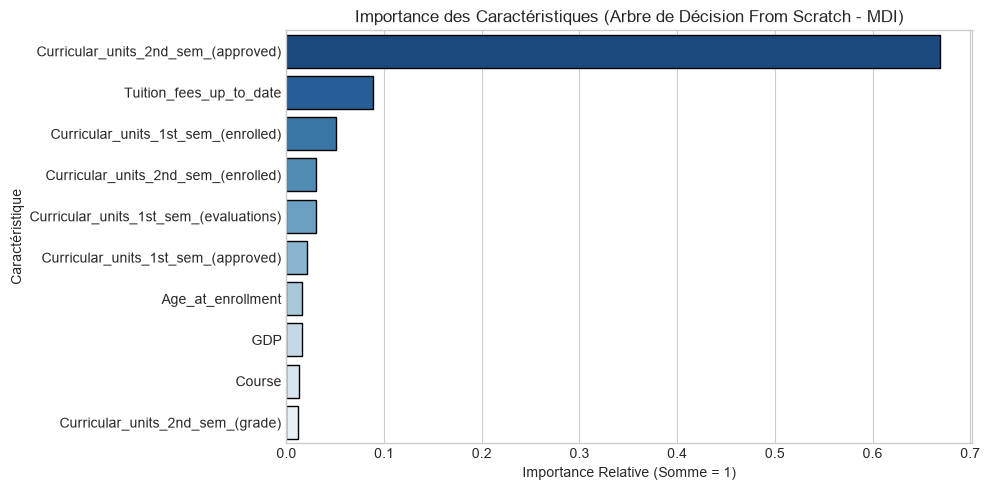


Variables sélectionnées pour la suite du pipeline (8) :
['Curricular_units_2nd_sem_(approved)', 'Tuition_fees_up_to_date', 'Curricular_units_1st_sem_(enrolled)', 'Curricular_units_2nd_sem_(enrolled)', 'Curricular_units_1st_sem_(evaluations)', 'Curricular_units_1st_sem_(approved)', 'Age_at_enrollment', 'GDP']


In [3]:
# Entraînement de l'Arbre codé From Scratch (profondeur max = 6 pour éviter l'overfitting)
tree = DecisionTreeClassifierScratch(max_depth=6, min_samples_split=20, criterion='gini')
tree.fit(X_tr, y_tr)

# Récupération et affichage des variables discriminantes
df_importances = tree.get_feature_importances()
print("Top 10 des caractéristiques les plus discriminantes :")
display(df_importances.head(10))

# Visualisation graphique du Top 10
plt.figure(figsize=(10, 5))
top10 = df_importances.head(10)
sns.barplot(data=top10, x='Importance', y='Feature', palette='Blues_r', edgecolor='black')
plt.title("Importance des Caractéristiques (Arbre de Décision From Scratch - MDI)")
plt.xlabel("Importance Relative (Somme = 1)")
plt.ylabel("Caractéristique")
plt.tight_layout()
plt.savefig("figures/feature_importance.png", dpi=300)
plt.show()

# Sélection des K meilleures variables (ex: les 8 plus importantes)
top_k = 8
selected_features = df_importances['Feature'].head(top_k).tolist()
print(f"\nVariables sélectionnées pour la suite du pipeline ({top_k}) :")
print(selected_features)

COMPARAISON RÉGRESSION LOGISTIQUE VS SVM

--- Tâche 2 : Entraînement et Comparaison sur les 8 variables retenues ---


/home/yaasin-ayadi/python/data/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Modèle,Accuracy,F1-Score (Macro),F1-Score (Pondéré)
0,Régression Logistique,0.727684,0.685302,0.740436
1,SVM (Noyau RBF),0.725424,0.688947,0.736784



--- RAPPORT RÉGRESSION LOGISTIQUE ---
              precision    recall  f1-score   support

     Dropout       0.82      0.69      0.75       284
    Enrolled       0.40      0.59      0.48       159
    Graduate       0.86      0.80      0.83       442

    accuracy                           0.73       885
   macro avg       0.69      0.69      0.69       885
weighted avg       0.76      0.73      0.74       885


--- RAPPORT SVM (NOYAU RBF) ---
              precision    recall  f1-score   support

     Dropout       0.84      0.67      0.74       284
    Enrolled       0.42      0.64      0.51       159
    Graduate       0.84      0.79      0.81       442

    accuracy                           0.73       885
   macro avg       0.70      0.70      0.69       885
weighted avg       0.76      0.73      0.74       885



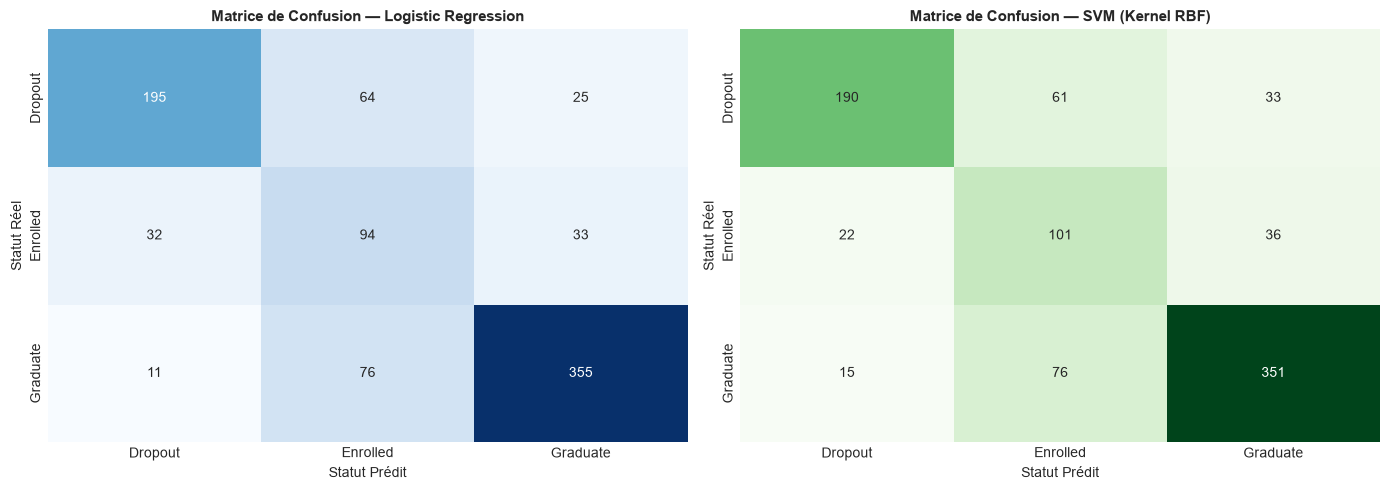

[FIGURE] Sauvegardée dans : figures/confusion_matrices.png


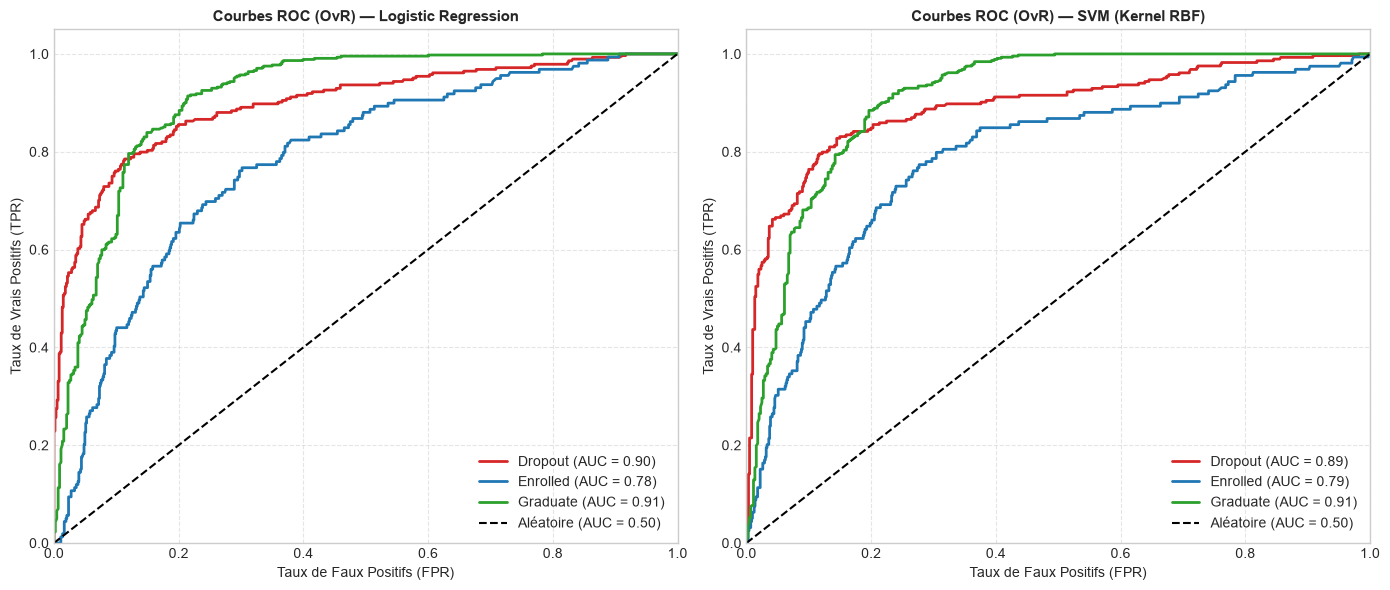

[FIGURE] Sauvegardée dans : figures/roc_curves.png


In [4]:
from src.supervised_models import train_and_evaluate_models
from src.evaluation_viz import plot_confusion_matrices, plot_multiclass_roc_curves

print("--- Tâche 2 : Entraînement et Comparaison sur les 8 variables retenues ---")

# Entraînement et calcul des métriques
resultats_sup, df_comparatif = train_and_evaluate_models(X_tr_sc, y_tr, X_te_sc, y_te, selected_features)

# Affichage du tableau comparatif
display(df_comparatif)

# Affichage des rapports détaillés
print("\n--- RAPPORT RÉGRESSION LOGISTIQUE ---")
print(resultats_sup['Logistic Regression']['report'])

print("\n--- RAPPORT SVM (NOYAU RBF) ---")
print(resultats_sup['SVM (Kernel RBF)']['report'])

# Tracé des deux figures obligatoires
plot_confusion_matrices(resultats_sup)
plot_multiclass_roc_curves(resultats_sup, y_te)